Import Libraries and Load Dataset

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

df = pd.read_csv("FakeNewsNet.csv")

df.head()

,title,news_url,source_domain,tweet_num,real
0,Kandi Burruss Explodes Over Rape Accusation on...,http://toofab.com/2017/05/08/real-housewives-a...,toofab.com,42,1
1,People's Choice Awards 2018: The best red carp...,https://www.today.com/style/see-people-s-choic...,www.today.com,0,1
2,Sophia Bush Sends Sweet Birthday Message to 'O...,https://www.etonline.com/news/220806_sophia_bu...,www.etonline.com,63,1
3,Colombian singer Maluma sparks rumours of inap...,https://www.dailymail.co.uk/news/article-33655...,www.dailymail.co.uk,20,1
4,Gossip Girl 10 Years Later: How Upper East Sid...,https://www.zerchoo.com/entertainment/gossip-g...,www.zerchoo.com,38,1


prepare text data

In [2]:
df = df.dropna(subset=['title', 'real'])

df['title'] = df['title'].astype(str)

df['real'] = pd.to_numeric(df['real'])

X = df['title']
y = df['real']

print("Total Articles:", len(df))
print("\nClass Distribution:")
print(y.value_counts())

Total Articles: 23196

Class Distribution:
real
1    17441
0     5755
Name: count, dtype: int64


Split Dataset into Training and Testing Sets

In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Samples:", len(X_train))
print("Testing Samples:", len(X_test))

Training Samples: 18556
Testing Samples: 4640


Apply Different Weighting Schemes

In [4]:
models = {
    'Count Vectorization': CountVectorizer(
        stop_words='english'
    ),

    'TF-IDF Standard': TfidfVectorizer(
        stop_words='english',
        use_idf=True,
        sublinear_tf=False
    ),

    'TF-IDF Sublinear': TfidfVectorizer(
        stop_words='english',
        use_idf=True,
        sublinear_tf=True
    ),

    'TF Only': TfidfVectorizer(
        stop_words='english',
        use_idf=False
    )
}

Train Models and Evaluate Performance

In [5]:
results = []

for name, vectorizer in models.items():

    pipeline = Pipeline([
        ('vectorizer', vectorizer),
        ('classifier', LogisticRegression(max_iter=1000))
    ])

    pipeline.fit(X_train, y_train)

    y_pred = pipeline.predict(X_test)

    results.append({
        'Method': name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred, zero_division=0),
        'Recall': recall_score(y_test, y_pred, zero_division=0),
        'F1_Score': f1_score(y_test, y_pred, zero_division=0)
    })

results_df = pd.DataFrame(results)

display(results_df.round(4))

,Method,Accuracy,Precision,Recall,F1_Score
0,Count Vectorization,0.8478,0.8690,0.9392,0.9028
1,TF-IDF Standard,0.8455,0.8509,0.9633,0.9036
2,TF-IDF Sublinear,0.8446,0.8507,0.9622,0.9030
3,TF Only,0.8433,0.8509,0.9599,0.9021


Compare Classification Accuracy

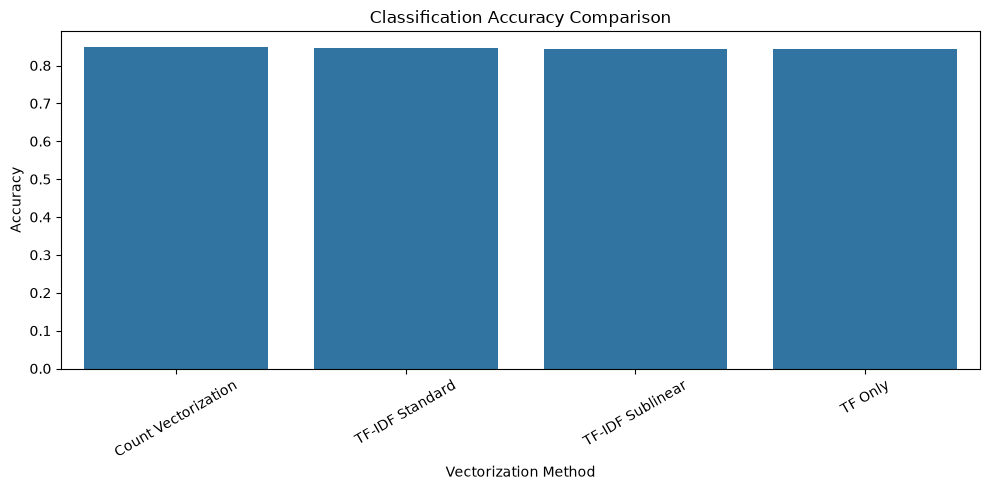

In [6]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=results_df,
    x='Method',
    y='Accuracy'
)

plt.title("Classification Accuracy Comparison")
plt.xlabel("Vectorization Method")
plt.ylabel("Accuracy")

plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

Compare Precision, Recall and F1-Score

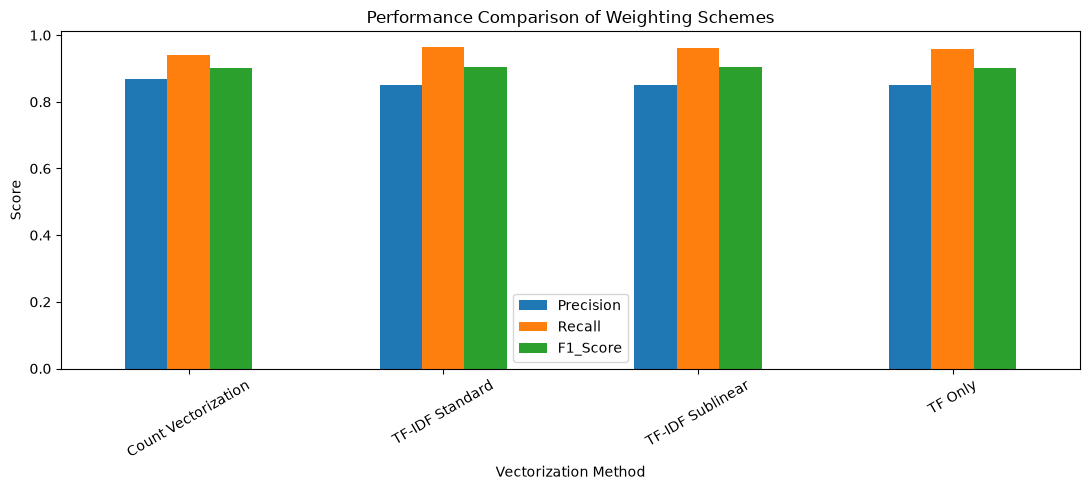

In [7]:
results_df.set_index('Method')[
    ['Precision', 'Recall', 'F1_Score']
].plot(kind='bar', figsize=(11, 5))

plt.title("Performance Comparison of Weighting Schemes")
plt.xlabel("Vectorization Method")
plt.ylabel("Score")

plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

Identify the Best Performing Method

In [8]:
best_model = results_df.loc[
    results_df['F1_Score'].idxmax()
]

print("Best Performing Method:")
print(best_model)

print("\nHighest Accuracy:")
print(results_df.loc[
    results_df['Accuracy'].idxmax()
])

Best Performing Method:
Method       TF-IDF Standard
Accuracy            0.845474
Precision           0.850886
Recall              0.963313
F1_Score            0.903616
Name: 1, dtype: object

Highest Accuracy:
Method       Count Vectorization
Accuracy                0.847845
Precision                  0.869
Recall                  0.939238
F1_Score                0.902755
Name: 0, dtype: object


Final Results

In [9]:
print("TF-IDF VECTORIZATION ANALYSIS")

print("\nTotal Articles:", len(df))

print("\nClassification Performance:")
display(results_df.round(4))

print("\nBest Method Based on F1-Score:")
print(best_model['Method'])

print("Best F1-Score:", round(best_model['F1_Score'], 4))

TF-IDF VECTORIZATION ANALYSIS

Total Articles: 23196

Classification Performance:


,Method,Accuracy,Precision,Recall,F1_Score
0,Count Vectorization,0.8478,0.8690,0.9392,0.9028
1,TF-IDF Standard,0.8455,0.8509,0.9633,0.9036
2,TF-IDF Sublinear,0.8446,0.8507,0.9622,0.9030
3,TF Only,0.8433,0.8509,0.9599,0.9021



Best Method Based on F1-Score:
TF-IDF Standard
Best F1-Score: 0.9036
